# FMCG lakehouse: querying GCS through Hive with PySpark

Run this notebook with the **FMCG PySpark (Spark 4.0.1, GCS + Hive)** kernel. When the kernel starts, it creates:
- `spark`: a SparkSession with the Google Cloud Storage connector and the Hive metastore (the same settings as the pipeline jobs);
- `F`: `pyspark.sql.functions`.

The data covers **three years of daily drops (14 Nov 2023 to 13 Nov 2026)**. Three Hive databases are available:

| Database | Bucket | Partitions |
|---|---|---|
| `datalake` | `gs://fmcg-datalake` | `year`, `month`, `day` |
| `mart` | `gs://fmcg-mart` | `year`, `week` (ISO) |
| `qa` | `gs://fmcg-mart/_qa` | `run_id` (QA check results) |

Shell cells such as `!gsutil ls -lh gs://fmcg-datalake/` browse the buckets (section 8).

Always filter on the partition columns: Spark then reads only those GCS folders.

In [1]:
spark.version, spark.catalog.currentDatabase()

('4.0.1', 'default')

## 0. Configure the notebook for GCS (`gsutil`, `gcloud storage`, Spark)

This cell points the Google Cloud CLI at the project's GCS: the local emulator by default, or real GCS when `GCS_MODE=real`.
- It creates (once) a separate gcloud configuration called `fmcg-emulator` and selects it **only for this notebook**, so your default gcloud setup is not changed.
- It makes `gsutil` run through `gcloud storage`, which supports the emulator endpoint.
- It reuses the `spark` session the kernel started; if this notebook runs on another kernel, it creates one.

In [2]:
import os, subprocess, sys
from pathlib import Path

REPO = Path(os.environ.get("FMCG_REPO", Path.cwd().parent)).resolve()
sys.path.insert(0, str(REPO))
GCS_MODE = os.environ.setdefault("GCS_MODE", "emulator")

if GCS_MODE == "emulator":
    # one-time: named gcloud configuration "fmcg-emulator" -> http://localhost:4443 (no login needed)
    subprocess.run([str(REPO / "scripts" / "setup_gcloud_emulator.sh")], check=True, capture_output=True)
    os.environ["CLOUDSDK_ACTIVE_CONFIG_NAME"] = "fmcg-emulator"        # only this notebook's shell commands use it
    os.environ["BOTO_CONFIG"] = str(REPO / ".gcloud" / "boto.cfg")      # gsutil -> gcloud storage (emulator-aware)
else:
    os.environ.pop("CLOUDSDK_ACTIVE_CONFIG_NAME", None)                 # real GCS: your normal gcloud login/project
os.environ["CLOUDSDK_COMPONENT_MANAGER_DISABLE_UPDATE_CHECK"] = "1"     # no "updates available" banner in outputs

if "spark" not in globals():                                           # kernel already created it; other kernels: create now
    from common.config import get_spark
    from pyspark.sql import functions as F
    spark = get_spark("jupyter-fmcg")

print("GCS mode         :", GCS_MODE)
print("gcloud config    :", os.environ.get("CLOUDSDK_ACTIVE_CONFIG_NAME", "default"))
print("spark            :", spark.version)

GCS mode         : emulator
gcloud config    : fmcg-emulator
spark            : 4.0.1


In [3]:
!gcloud storage ls
!gsutil ls -lh gs://fmcg-datalake/

gs://fmcg-datalake/
gs://fmcg-landing/
gs://fmcg-mart/


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


                                  gs://fmcg-datalake/_manifests/
                                  gs://fmcg-datalake/customers/
                                  gs://fmcg-datalake/promotions/
                                  gs://fmcg-datalake/stores/
                                  gs://fmcg-datalake/transactions/
TOTAL: 0 objects, 0 bytes (0 B)


## 1. What is in each layer (`spark.sql(...).show(10, 0)`)

In [4]:
spark.sql("show databases").show(10, 0)
spark.sql("show tables in datalake").show(10, 0)
spark.sql("show tables in mart").show(10, 0)
spark.sql("show tables in qa").show(10, 0)

+---------+
|namespace|
+---------+
|datalake |
|default  |
|mart     |
|qa       |
+---------+



+---------+------------+-----------+
|namespace|tableName   |isTemporary|
+---------+------------+-----------+
|datalake |customers   |false      |
|datalake |promotions  |false      |
|datalake |stores      |false      |
|datalake |transactions|false      |
+---------+------------+-----------+

+---------+------------------------------+-----------+
|namespace|tableName                     |isTemporary|
+---------+------------------------------+-----------+
|mart     |category_brand_weekly         |false      |
|mart     |company_weekly_kpis           |false      |
|mart     |customer_tier_weekly          |false      |
|mart     |fact_sales                    |false      |
|mart     |promotion_weekly_effectiveness|false      |
|mart     |store_weekly_performance      |false      |
+---------+------------------------------+-----------+

+---------+---------------+-----------+
|namespace|tableName      |isTemporary|
+---------+---------------+-----------+
|qa       |datalake_checks|false

In [5]:
spark.sql("show partitions mart.fact_sales").show(10, 0)

+-----------------+
|partition        |
+-----------------+
|year=2023/week=46|
|year=2023/week=47|
|year=2023/week=48|
|year=2023/week=49|
|year=2023/week=50|
|year=2023/week=51|
|year=2023/week=52|
|year=2024/week=1 |
|year=2024/week=10|
|year=2024/week=11|
+-----------------+
only showing top 10 rows


In [6]:
# where a table's files live in GCS, and how it is stored
spark.sql("describe formatted mart.store_weekly_performance") \
     .where("col_name in ('Type', 'Provider', 'Location', 'Partition Provider')") \
     .show(10, 0)

+------------------+---------------------------------------+-------+
|col_name          |data_type                              |comment|
+------------------+---------------------------------------+-------+
|Type              |EXTERNAL                               |       |
|Provider          |hive                                   |       |
|Location          |gs://fmcg-mart/store_weekly_performance|       |
|Partition Provider|Catalog                                |       |
+------------------+---------------------------------------+-------+



## 2. Raw datalake with `spark.table(...)`

In [7]:
tx = spark.table("datalake.transactions")
tx.printSchema()

root
 |-- transaction_id: string (nullable = true)
 |-- line_no: integer (nullable = true)
 |-- transaction_ts: timestamp (nullable = true)
 |-- store_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- sku: string (nullable = true)
 |-- product_name: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- category: string (nullable = true)
 |-- sub_category: string (nullable = true)
 |-- pack_size: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- unit_price: decimal(12,2) (nullable = true)
 |-- discount_amount: decimal(12,2) (nullable = true)
 |-- promotion_id: string (nullable = true)
 |-- payment_mode: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- filename: string (nullable = true)
 |-- modified_dttm: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day: integer (nullable = true)



In [8]:
# one day's raw POS lines (partition pruning: only gs://fmcg-datalake/transactions/year=2026/month=11/day=8/ is read)
tx.where("year = 2026 and month = 11 and day = 8") \
  .select("transaction_id", "line_no", "transaction_ts", "store_id", "product_name", "quantity", "unit_price", "filename", "modified_dttm") \
  .show(10, 0)

+----------------+-------+-------------------+--------+-------------------+--------+----------+----------------------------+--------------------------+
|transaction_id  |line_no|transaction_ts     |store_id|product_name       |quantity|unit_price|filename                    |modified_dttm             |
+----------------+-------+-------------------+--------+-------------------+--------+----------+----------------------------+--------------------------+
|T202611080430022|1      |2026-11-08 21:00:05|ST043   |Masala Noodles     |1       |194.00    |transactions_20261108.csv.gz|2026-11-13 01:18:47.571718|
|T202611080210015|1      |2026-11-08 10:28:30|ST021   |Lemon Dishwash Bar |1       |69.00     |transactions_20261108.csv.gz|2026-11-13 01:18:47.571718|
|T202611080400033|2      |2026-11-08 13:41:42|ST040   |Fresh Paneer       |3       |110.00    |transactions_20261108.csv.gz|2026-11-13 01:18:47.571718|
|T202611080090166|4      |2026-11-08 21:20:53|ST009   |Fresh Paneer       |1       |110.

In [9]:
# lines and gross value per drop date, with the DataFrame API
# lines and gross value per month, with the DataFrame API (3 years of daily partitions)
(tx.groupBy("year", "month")
   .agg(F.countDistinct("day").alias("days"), F.count("*").alias("lines"),
        F.round(F.sum(F.col("quantity") * F.col("unit_price")), 0).alias("gross_inr"))
   .orderBy("year", "month")
   .show(40, 0))

+----+-----+----+------+---------+
|year|month|days|lines |gross_inr|
+----+-----+----+------+---------+
|2023|11   |17  |46476 |17404045 |
|2023|12   |31  |89544 |33488499 |
|2024|1    |31  |85503 |32298392 |
|2024|2    |29  |81376 |30718366 |
|2024|3    |31  |91959 |35081413 |
|2024|4    |30  |84715 |32404596 |
|2024|5    |31  |88178 |34014816 |
|2024|6    |30  |88819 |34309514 |
|2024|7    |31  |81396 |32035299 |
|2024|8    |31  |84435 |32684367 |
|2024|9    |30  |90912 |35733987 |
|2024|10   |31  |103207|41451806 |
|2024|11   |30  |95577 |37796306 |
|2024|12   |31  |96828 |38287080 |
|2025|1    |31  |94983 |37586132 |
|2025|2    |28  |87596 |34552195 |
|2025|3    |31  |101860|40895904 |
|2025|4    |30  |94590 |38030184 |
|2025|5    |31  |99118 |40322195 |
|2025|6    |30  |97272 |39272977 |
|2025|7    |31  |90579 |37520127 |
|2025|8    |31  |94244 |38478248 |
|2025|9    |30  |98872 |40455826 |
|2025|10   |31  |119398|51347388 |
|2025|11   |30  |102547|41875431 |
|2025|12   |31  |106

## 3. Business questions on the mart with `spark.sql(...)`

In [10]:
spark.sql("""
    select week, region,
           round(sum(net_sales))           as net_sales_inr,
           round(sum(prev_week_net_sales)) as prev_week_inr,
           round(100 * (sum(net_sales) / sum(prev_week_net_sales) - 1), 1) as wow_pct
    from mart.store_weekly_performance
    where year = 2026 and week in (44, 45)
    group by week, region
    order by week, net_sales_inr desc
""").show(10, 0)

+----+------+-------------+-------------+-------+
|week|region|net_sales_inr|prev_week_inr|wow_pct|
+----+------+-------------+-------------+-------+
|44  |East  |3964159      |3623656      |9.4    |
|44  |North |3694788      |3285922      |12.4   |
|44  |West  |3012813      |2488091      |21.1   |
|44  |South |2657746      |2337400      |13.7   |
|45  |East  |5733835      |3964159      |44.6   |
|45  |North |5247405      |3694788      |42.0   |
|45  |West  |4432313      |3012813      |47.1   |
|45  |South |4008706      |2657746      |50.8   |
+----+------+-------------+-------------+-------+



In [11]:
# top stores in the Diwali week (ISO week 45), using spark.table + DataFrame API
(spark.table("mart.store_weekly_performance")
      .where("year = 2026 and week = 45")
      .select("store_name", "region", "store_format", "net_sales", "avg_basket_value", "sales_per_sqft", "wow_growth_pct", "rank_in_region")
      .orderBy(F.desc("net_sales"))
      .show(10, 0))

+--------------------------+------+------------+----------+----------------+--------------+--------------+--------------+
|store_name                |region|store_format|net_sales |avg_basket_value|sales_per_sqft|wow_growth_pct|rank_in_region|
+--------------------------+------+------------+----------+----------------+--------------+--------------+--------------+
|Lucknow Hypermarket 9     |North |Hypermarket |1059419.90|1551.13         |23.22         |37.55         |1             |
|Kolkata Hypermarket 40    |East  |Hypermarket |1045406.28|1628.36         |23.47         |49.47         |1             |
|Kochi Hypermarket 37      |South |Hypermarket |1025541.95|1535.24         |21.90         |53.72         |1             |
|Chennai Hypermarket 34    |South |Hypermarket |1015504.08|1497.79         |17.35         |42.87         |2             |
|Ahmedabad Hypermarket 24  |West  |Hypermarket |1009939.89|1520.99         |23.48         |52.83         |1             |
|Bhubaneswar Hypermarket

In [12]:
spark.sql("""
    select category,
           round(sum(net_sales)) as net_sales_inr,
           round(100 * sum(net_sales) / sum(sum(net_sales)) over (), 1) as share_pct,
           round(100 * (sum(net_sales) / sum(prev_week_net_sales) - 1), 1) as wow_pct
    from mart.category_brand_weekly
    where year = 2026 and week = 45
    group by category
    order by net_sales_inr desc
""").show(10, 0)

+-------------+-------------+---------+-------+
|category     |net_sales_inr|share_pct|wow_pct|
+-------------+-------------+---------+-------+
|Foods        |7195099      |37.0     |44.1   |
|Personal Care|3860846      |19.9     |41.1   |
|Beverages    |3131291      |16.1     |43.3   |
|Home Care    |2858563      |14.7     |44.1   |
|Dairy        |2376460      |12.2     |66.1   |
+-------------+-------------+---------+-------+



In [13]:
# did the promotions pay for their discount?
spark.sql("""
    select week, promo_name, brand, discount_pct, promo_units, unit_uplift_pct,
           discount_cost, incremental_net_sales, roi
    from mart.promotion_weekly_effectiveness
    where year = 2026 and week between 43 and 46
    order by week, roi desc
""").show(10, 0)

+----+--------------------------+--------------+------------+-----------+---------------+-------------+---------------------+----+
|week|promo_name                |brand         |discount_pct|promo_units|unit_uplift_pct|discount_cost|incremental_net_sales|roi |
+----+--------------------------+--------------+------------+-----------+---------------+-------------+---------------------+----+
|44  |Diwali Sweets Bonanza 2026|Mithas        |20          |2330       |90.9           |281230.00    |535701.83            |1.9 |
|44  |Festive Clean Home 2026   |Kleanso       |15          |2789       |46.7           |72208.50     |130260.80            |1.8 |
|45  |Staples Stock-Up 2026     |Annapurna Gold|10          |3776       |88.4           |254993.30    |1077023.78           |4.22|
|45  |Ghee for Diwali 2026      |Gaukul        |12          |10627      |106.0          |294118.80    |1110066.70           |3.77|
|45  |Festive Clean Home 2026   |Kleanso       |15          |3819       |95.2      

In [14]:
spark.table("mart.customer_tier_weekly").where("year = 2026 and week = 45") \
     .orderBy(F.desc("net_sales")).show(10, 0)

+--------------+------------+----------------+-------+-----+----------+----------------------+------------------------+------------------+----+----+
|customer_type |loyalty_tier|active_customers|baskets|units|net_sales |avg_spend_per_customer|avg_baskets_per_customer|share_of_sales_pct|year|week|
+--------------+------------+----------------+-------+-----+----------+----------------------+------------------------+------------------+----+----+
|walk-in       |Walk-in     |0               |3768   |22332|5920149.59|NULL                  |NULL                    |30.48             |2026|45  |
|loyalty member|Silver      |1047            |2782   |16178|4295919.79|4103.08               |2.66                    |22.12             |2026|45  |
|loyalty member|Gold        |955             |2538   |14827|3949660.04|4135.77               |2.66                    |20.34             |2026|45  |
|loyalty member|Platinum    |858             |2301   |13612|3563637.31|4153.42               |2.68        

## 4. Mixing both styles: a DataFrame registered as a temporary view

In [15]:
daily = (spark.table("mart.fact_sales")
              .where("year = 2026 and week in (44, 45)")
              .groupBy("sale_date", "day_of_week")
              .agg(F.round(F.sum("net_amount"), 0).alias("net_sales_inr"),
                   F.countDistinct("transaction_id").alias("baskets")))
daily.createOrReplaceTempView("daily_sales")

spark.sql("""
    select sale_date, day_of_week, net_sales_inr, baskets,
           round(net_sales_inr / baskets, 0) as avg_basket_inr
    from daily_sales
    order by sale_date
""").show(14, 0)

+----------+-----------+-------------+-------+--------------+
|sale_date |day_of_week|net_sales_inr|baskets|avg_basket_inr|
+----------+-----------+-------------+-------+--------------+
|2026-10-26|Monday     |1674801      |1091   |1535          |
|2026-10-27|Tuesday    |1447547      |957    |1513          |
|2026-10-28|Wednesday  |1518380      |1017   |1493          |
|2026-10-29|Thursday   |1636436      |1102   |1485          |
|2026-10-30|Friday     |1889139      |1230   |1536          |
|2026-10-31|Saturday   |2546783      |1677   |1519          |
|2026-11-01|Sunday     |2616421      |1697   |1542          |
|2026-11-02|Monday     |1898744      |1289   |1473          |
|2026-11-03|Tuesday    |2012984      |1271   |1584          |
|2026-11-04|Wednesday  |2180968      |1414   |1542          |
|2026-11-05|Thursday   |2491886      |1545   |1613          |
|2026-11-06|Friday     |2494834      |1618   |1542          |
|2026-11-07|Saturday   |4055041      |2577   |1574          |
|2026-11

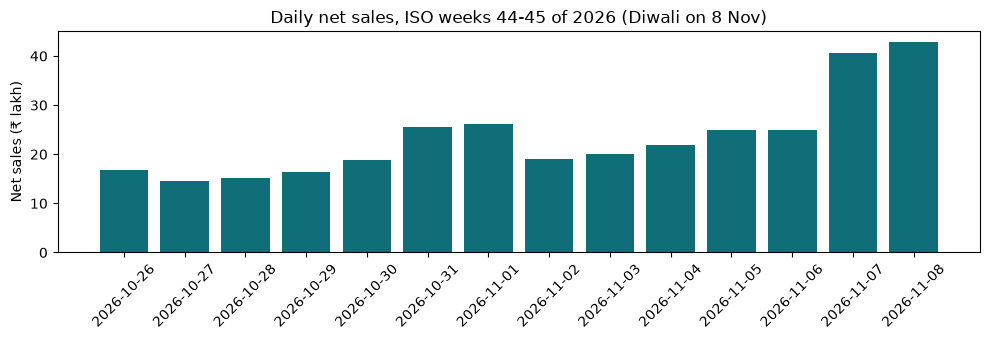

In [16]:
import matplotlib.pyplot as plt

pdf = spark.table("daily_sales").orderBy("sale_date").toPandas()
fig, ax = plt.subplots(figsize=(10, 3.5))
# Spark decimals arrive as Python Decimal objects: convert to float for plotting
ax.bar(pdf["sale_date"].astype(str), pdf["net_sales_inr"].astype(float) / 1e5, color="#0f6e78")
ax.set_ylabel("Net sales (₹ lakh)")
ax.set_title("Daily net sales, ISO weeks 44-45 of 2026 (Diwali on 8 Nov)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5. Proof of partition pruning

The physical plan lists `PartitionFilters`. Spark lists only the `year=2026/week=45` folder in GCS.

In [17]:
spark.sql("select sum(net_amount) from mart.fact_sales where year = 2026 and week = 45").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[], functions=[sum(net_amount#827)])
   +- Exchange SinglePartition, ENSURE_REQUIREMENTS, [plan_id=707]
      +- HashAggregate(keys=[], functions=[partial_sum(net_amount#827)])
         +- Project [net_amount#827]
            +- FileScan parquet spark_catalog.mart.fact_sales[net_amount#827,year#834,week#835] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[gs://fmcg-mart/fact_sales/year=2026/week=45], PartitionFilters: [isnotnull(year#834), isnotnull(week#835), (year#834 = 2026), (week#835 = 45)], PushedFilters: [], ReadSchema: struct<net_amount:decimal(14,2)>




## 6. Three years of weekly KPIs: week-on-week and year-on-year

In [18]:
spark.sql("""
    select year, week, week_start, week_end, stores_trading, net_sales,
           wow_growth_pct, yoy_growth_pct, online_share_pct
    from mart.company_weekly_kpis
    where (year = 2026 and week between 40 and 46) or (year = 2025 and week between 42 and 45)
    order by year, week
""").show(20, 0)

+----+----+----------+----------+--------------+-----------+--------------+--------------+----------------+
|year|week|week_start|week_end  |stores_trading|net_sales  |wow_growth_pct|yoy_growth_pct|online_share_pct|
+----+----+----------+----------+--------------+-----------+--------------+--------------+----------------+
|2025|42  |2025-10-13|2025-10-19|46            |13630277.72|32.28         |64.72         |12.5            |
|2025|43  |2025-10-20|2025-10-26|46            |12411467.21|-8.94         |22.51         |12.79           |
|2025|44  |2025-10-27|2025-11-02|46            |9890079.00 |-20.31        |-20.77        |12.59           |
|2025|45  |2025-11-03|2025-11-09|46            |9356644.00 |-5.39         |11.22         |12.33           |
|2026|40  |2026-09-28|2026-10-04|49            |11442677.00|-4.48         |22.28         |14.28           |
|2026|41  |2026-10-05|2026-10-11|49            |11412617.00|-0.26         |10.75         |13.53           |
|2026|42  |2026-10-12|2026-1

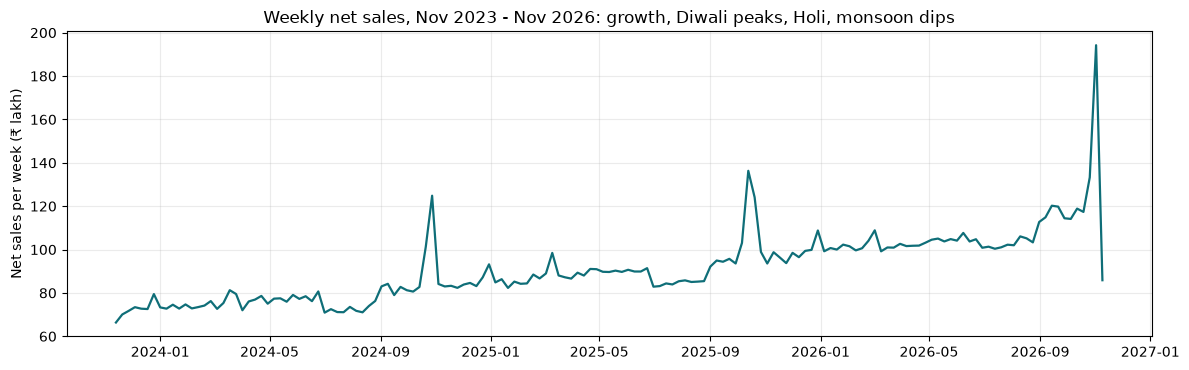

In [19]:
import matplotlib.pyplot as plt

kpi = spark.table("mart.company_weekly_kpis").orderBy("week_start").toPandas()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(kpi["week_start"], kpi["net_sales"].astype(float) / 1e5, color="#0f6e78", linewidth=1.6)
ax.set_ylabel("Net sales per week (₹ lakh)")
ax.set_title("Weekly net sales, Nov 2023 - Nov 2026: growth, Diwali peaks, Holi, monsoon dips")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Data quality results (`qa` database)

The QA DAGs save every check to Hive. A company-level week-on-week change beyond ±20%, or a year-on-year change beyond ±40%, fails `fmcg_4_mart_qa`. Region and category breaches are recorded as warnings.

In [20]:
spark.sql("""
    select check_name, level, status, count(*) as evaluations
    from qa.mart_checks
    group by check_name, level, status
    order by check_name, level, status
""").show(30, 0)

+-------------+--------+-------+-----------+
|check_name   |level   |status |evaluations|
+-------------+--------+-------+-----------+
|pk_uniqueness|table   |PASS   |942        |
|wow_change   |category|PASS   |748        |
|wow_change   |category|SKIPPED|5          |
|wow_change   |category|WARN   |32         |
|wow_change   |company |FAIL   |7          |
|wow_change   |company |PASS   |149        |
|wow_change   |company |SKIPPED|1          |
|wow_change   |region  |PASS   |598        |
|wow_change   |region  |SKIPPED|4          |
|wow_change   |region  |WARN   |26         |
|yoy_change   |category|PASS   |515        |
|yoy_change   |category|SKIPPED|260        |
|yoy_change   |category|WARN   |10         |
|yoy_change   |company |FAIL   |2          |
|yoy_change   |company |PASS   |103        |
|yoy_change   |company |SKIPPED|52         |
|yoy_change   |region  |PASS   |407        |
|yoy_change   |region  |SKIPPED|208        |
|yoy_change   |region  |WARN   |13         |
+---------

In [21]:
# company-level weeks that breached a threshold, with the numbers behind them
spark.sql("""
    select check_name, concat(iso_year, '-W', lpad(iso_week, 2, '0')) as week, round(observed, 1) as change_pct, detail
    from qa.mart_checks
    where level = 'company' and status = 'FAIL'
    order by iso_year, iso_week, check_name
""").show(40, 0)

+----------+--------+----------+------------------------------------------------------------------------------+
|check_name|week    |change_pct|detail                                                                        |
+----------+--------+----------+------------------------------------------------------------------------------+
|wow_change|2024-W43|22.4      |net_sales=10,130,710 prev_week_net_sales=8,274,703 change=+22.4% (limit ±20%) |
|wow_change|2024-W44|23.2      |net_sales=12,482,976 prev_week_net_sales=10,130,710 change=+23.2% (limit ±20%)|
|wow_change|2024-W45|-32.6     |net_sales=8,412,872 prev_week_net_sales=12,482,976 change=-32.6% (limit ±20%) |
|wow_change|2025-W42|32.3      |net_sales=13,630,278 prev_week_net_sales=10,304,453 change=+32.3% (limit ±20%)|
|yoy_change|2025-W42|64.7      |net_sales=13,630,278 prev_year_net_sales=8,274,703 change=+64.7% (limit ±40%) |
|wow_change|2025-W44|-20.3     |net_sales=9,890,079 prev_week_net_sales=12,411,467 change=-20.3% (limit 

In [22]:
spark.table("qa.datalake_checks").groupBy("check_name", "table_name", "status").count() \
     .orderBy("check_name", "table_name", "status").show(20, 0)

+-------------+------------+------+-----+
|check_name   |table_name  |status|count|
+-------------+------------+------+-----+
|null_keys    |customers   |PASS  |1096 |
|null_keys    |promotions  |PASS  |405  |
|null_keys    |stores      |PASS  |1096 |
|null_keys    |transactions|PASS  |1096 |
|pk_uniqueness|customers   |PASS  |1096 |
|pk_uniqueness|promotions  |PASS  |405  |
|pk_uniqueness|stores      |PASS  |1096 |
|pk_uniqueness|transactions|WARN  |1096 |
|row_counts   |customers   |PASS  |1096 |
|row_counts   |promotions  |PASS  |405  |
|row_counts   |stores      |PASS  |1096 |
|row_counts   |transactions|PASS  |1096 |
+-------------+------------+------+-----+



## 8. Browse the buckets with `gsutil` / `gcloud storage`

Shell commands work in cells with `!`. The kernel points the Google Cloud CLI at the local GCS emulator through a separate gcloud configuration (`fmcg-emulator`), so your default gcloud setup is untouched. With real GCS, the same commands run against your project.

In [23]:
!gsutil ls -lh gs://fmcg-datalake/transactions/year=2026/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


                                  gs://fmcg-datalake/transactions/year=2026/month=1/
                                  gs://fmcg-datalake/transactions/year=2026/month=10/
                                  gs://fmcg-datalake/transactions/year=2026/month=11/
                                  gs://fmcg-datalake/transactions/year=2026/month=2/
                                  gs://fmcg-datalake/transactions/year=2026/month=3/
                                  gs://fmcg-datalake/transactions/year=2026/month=4/
                                  gs://fmcg-datalake/transactions/year=2026/month=5/
                                  gs://fmcg-datalake/transactions/year=2026/month=6/
                                  gs://fmcg-datalake/transactions/year=2026/month=7/
                                  gs://fmcg-datalake/transactions/year=2026/month=8/
                                  gs://fmcg-datalake/transactions/year=2026/month=9/
TOTAL: 0 objects, 0 bytes (0 B)


In [24]:
!gsutil du -sh gs://fmcg-landing gs://fmcg-datalake gs://fmcg-mart

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


55.57 MiB    gs://fmcg-landing


69.46 MiB    gs://fmcg-datalake


111.51 MiB   gs://fmcg-mart


In [25]:
# the raw daily drops in the landing bucket
!gsutil ls -l gs://fmcg-landing/transactions/2026/11/08/ gs://fmcg-landing/customers/2026/11/08/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


    163449  2026-11-12T19:48:11Z  gs://fmcg-landing/transactions/2026/11/08/transactions_20261108.csv.gz
TOTAL: 1 objects, 163449 bytes (159.62 KiB)


       507  2026-11-12T19:48:11Z  gs://fmcg-landing/customers/2026/11/08/customers_20261108.csv.gz
TOTAL: 1 objects, 507 bytes (507 B)


In [26]:
# one datalake partition = one GCS folder of Parquet files
!gsutil ls -lh gs://fmcg-datalake/transactions/year=2026/month=11/day=8/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


155.94 KiB  2026-11-12T19:49:56Z  gs://fmcg-datalake/transactions/year=2026/month=11/day=8/part-00003-2fa477f3-d7b5-461b-b59f-d3a9b35607b4.c000.snappy.parquet
TOTAL: 1 objects, 159684 bytes (155.94 KiB)


In [27]:
!gcloud storage ls gs://fmcg-mart/fact_sales/

gs://fmcg-mart/fact_sales/year=2023/
gs://fmcg-mart/fact_sales/year=2024/


gs://fmcg-mart/fact_sales/year=2025/
gs://fmcg-mart/fact_sales/year=2026/


In [28]:
# the reconciliation manifest written by the mart job
!gsutil cat gs://fmcg-mart/_manifests/2026/W45/manifest_20261108.json

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


{
  "iso_year": 2026,
  "iso_week": 45,
  "week_start": "2026-11-02",
  "last_day": "2026-11-08",
  "row_counts": {
    "fact_sales": 43293,
    "store_weekly_performance": 49,
    "category_brand_weekly": 29,
    "promotion_weekly_effectiveness": 4,
    "customer_tier_weekly": 5,
    "company_weekly_kpis": 1
  },
  "net_sales": 19422259.05,
  "checks": {
    "duplicates_removed": 213,
    "store_total_matches_fact": true,
    "category_total_matches_fact": true,
    "tier_total_matches_fact": true,
    "company_total_matches_fact": true,
    "every_line_has_store": true
  },
  "written_at": "2026-11-12T21:23:03.008860+00:00"
}

In [29]:
# Spark can read the raw .csv.gz straight from the landing bucket too
(spark.read.option("header", True)
      .csv("gs://fmcg-landing/transactions/2026/11/08/transactions_20261108.csv.gz")
      .select("transaction_id", "store_id", "product_name", "quantity", "unit_price", "payment_mode")
      .show(5, 0))

+----------------+--------+------------------+--------+----------+------------+
|transaction_id  |store_id|product_name      |quantity|unit_price|payment_mode|
+----------------+--------+------------------+--------+----------+------------+
|T202611080430022|ST043   |Masala Noodles    |1       |194.0     |Card        |
|T202611080210015|ST021   |Lemon Dishwash Bar|1       |69.0      |Wallet      |
|T202611080400033|ST040   |Fresh Paneer      |3       |110.0     |UPI         |
|T202611080090166|ST009   |Fresh Paneer      |1       |110.0     |UPI         |
|T202611080090137|ST009   |Lemon Soda        |2       |208.0     |UPI         |
+----------------+--------+------------------+--------+----------+------------+
only showing top 5 rows
